---
title: "Simulating Brownian motion / Wiener process model" 
author: "Sheng Long"
date: "10-19-25"
format: 
    html: 
        reference-location: margin
        citation-location: margin
        toc: true 
        html-math-method: katex 
draft: true
categories: [statistics, python]
title-block-banner: true
---

In [61]:
#| code-fold: true 
#| echo: false 
# check to make sure we're using the correct interpreter 
import sys 
print(sys.executable)


/Users/shenglong/Downloads/mika-long.github.io/posts/wiener/.venv/bin/python


In [1]:
#| code-fold: true 
import seaborn as sns 
import numpy as np 
import matplotlib.pyplot as plt 
import polars as pl 
# set seaborn style 
sns.set_style("whitegrid")
sns.set_palette("husl") 

<!-- - https://sites.me.ucsb.edu/~moehlis/APC591/tutorials/tutorial7/node2.html  -->

First we look at the "standard" Brownian motion, which "involves Brownian motion paths with zero mean and unit variance"^[Source: https://www.quantstart.com/articles/brownian-motion-simulation-with-python/ ]. The following recursion relation is for a Brownian motion path across $n$ points: $$W(t_{i+1}) = W(t_i) + \sqrt{t_{i+1}-t_i} Z_{i+1}$$ where $Z_{i+1}$ is sampled from the standard normal distribution. 

To see the paths clearly, we will start by plotting 50 paths, and "discretize" the unit time into 100 equal-sized steps^[That is, $t_{i+1}-t_i$ is fixed for all values of $i$.]. 

In [ ]:
# random number generator 
rng = np.random.default_rng(42)
paths = 50
points = 100
mu, sigma = 0.0, 1.0
Z = rng.normal(mu, sigma, (paths, points))

(50, 100)


In [3]:
#| code-fold: true 

# assume fixed time distance 
interval = [0.0, 1.0]
dt = (interval[1] - interval[0]) / (points - 1)
t_axis = np.linspace(interval[0], interval[1], points)

W = np.zeros((paths, points))
for idx in range(points - 1):
    real_idx = idx + 1
    W[:, real_idx] = W[:, real_idx - 1] + np.sqrt(dt) * Z[:, idx]

Plotting the Brownian motion: 

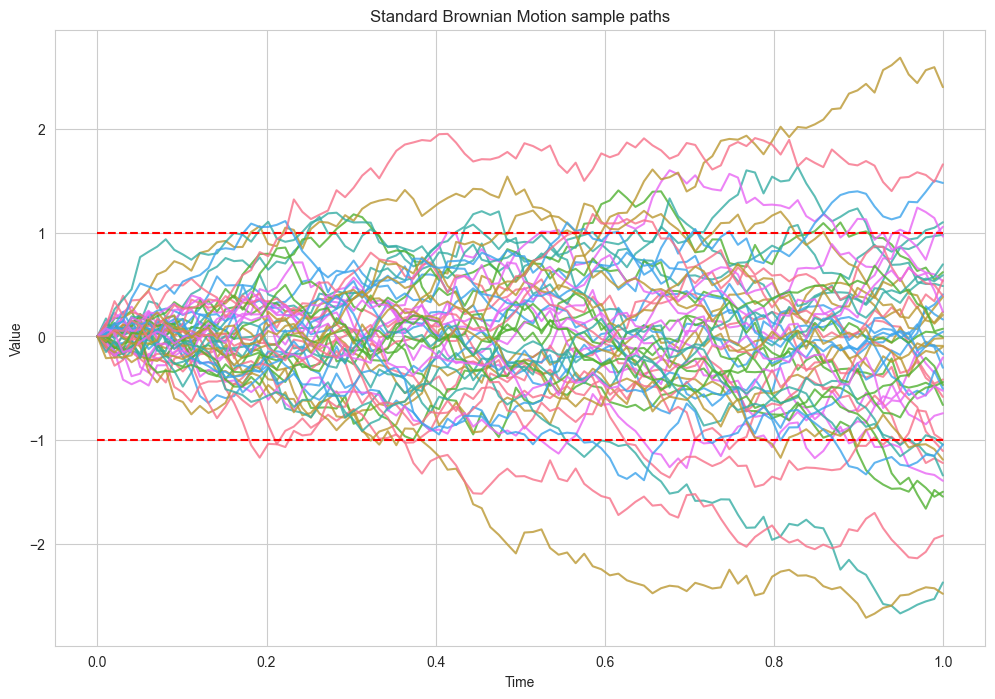

In [4]:
#| code-fold: true 
# Plotting 
fig, ax = plt.subplots(1, 1, figsize=(12, 8))
for path in range(paths):
    ax.plot(t_axis, W[path, :], alpha = 0.8)

# add horizontal lines 
ax.hlines(y = 1.0, xmin = 0, xmax = 1, color = "red", linestyle = "--")
ax.hlines(y = -1.0, xmin = 0, xmax = 1, color = "red", linestyle = "--")
ax.set_title("Standard Brownian Motion sample paths")
ax.set_xlabel("Time")
ax.set_ylabel("Value")
plt.show()

# First-passage time distribution 

Let's set 1 and -1 to be the upper and lower decision boundary. 

In [5]:
upper_boundary = 1.0 
lower_boundary = -1.0

first_passage_times = [] 

In [6]:
#| code-fold: true 
for path_idx in range(paths): 
    upper_crossings = np.where(W[path_idx, :] >= upper_boundary)
    lower_crossings = np.where(W[path_idx, :] <= lower_boundary) 
    if len(upper_crossings[0]) > 0 and len(lower_crossings[0]) > 0: 
        first_crossing = min(upper_crossings[0][0], lower_crossings[0][0])
    elif len(upper_crossings[0]) > 0: 
        first_crossing = upper_crossings[0][0]
    elif len(lower_crossings[0]) > 0: 
        first_crossing = lower_crossings[0][0]
    else: 
        # no crossing occured during the points 
        first_crossing = None 
    # convert to actual time 
    if first_crossing: 
        first_passage_time = t_axis[first_crossing] 
    else: 
        first_passage_time = None 
    first_passage_times.append(first_passage_time) 

In [7]:
pl.Series(first_passage_times).describe()


statistic,value
str,f64
"""count""",29.0
"""null_count""",21.0
"""mean""",0.526297
"""std""",0.280413
"""min""",0.181818
"""25%""",0.282828
"""50%""",0.494949
"""75%""",0.79798
"""max""",1.0


Plot and see the emprical distribution of first-passage times: 

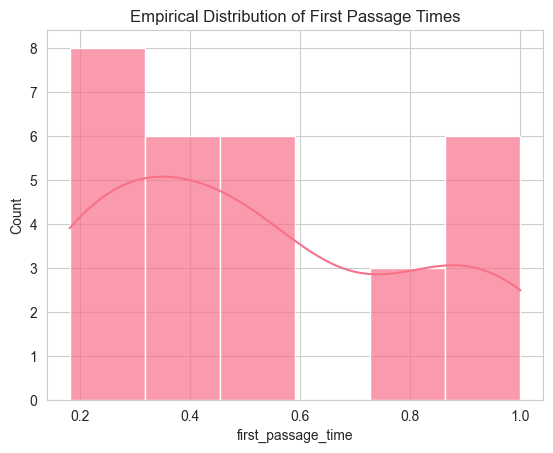

In [8]:
#| code-fold: true 
times_clean = (
    pl.Series(first_passage_times)
    .drop_nulls()
    .to_numpy()
)

# Create a DataFrame for seaborn
df_plot = pl.DataFrame({"first_passage_time": times_clean})

# Plot with seaborn
sns.histplot(data=df_plot, x="first_passage_time", kde=True, alpha=0.7)
plt.title("Empirical Distribution of First Passage Times")
plt.show()

Note that the above is only for 50 simulations. To get a better sense of the distribution we can rely on more simulations, e.g., 1000. 

In [20]:
#| code-fold: true 
# random number generator 
rng = np.random.default_rng(42)
paths = 1000
points = 100
mu, sigma = 0.0, 1.0
Z = rng.normal(mu, sigma, (paths, points))
interval = [0.0, 1.0]
dt = (interval[1] - interval[0]) / (points - 1)
t_axis = np.linspace(interval[0], interval[1], points)

W = np.zeros((paths, points))
for idx in range(points - 1):
    real_idx = idx + 1
    W[:, real_idx] = W[:, real_idx - 1] + np.sqrt(dt) * Z[:, idx]

first_passage_times = [] 

for path_idx in range(paths): 
    upper_crossings = np.where(W[path_idx, :] >= upper_boundary)
    lower_crossings = np.where(W[path_idx, :] <= lower_boundary) 
    if len(upper_crossings[0]) > 0 and len(lower_crossings[0]) > 0: 
        first_crossing = min(upper_crossings[0][0], lower_crossings[0][0])
    elif len(upper_crossings[0]) > 0: 
        first_crossing = upper_crossings[0][0]
    elif len(lower_crossings[0]) > 0: 
        first_crossing = lower_crossings[0][0]
    else: 
        # no crossing occured during the points 
        first_crossing = None 
    # convert to actual time 
    if first_crossing: 
        first_passage_time = t_axis[first_crossing] 
    else: 
        first_passage_time = None 
    first_passage_times.append(first_passage_time) 

In [21]:
pl.Series(first_passage_times).describe()

statistic,value
str,f64
"""count""",602.0
"""null_count""",398.0
"""mean""",0.552904
"""std""",0.237292
"""min""",0.111111
"""25%""",0.353535
"""50%""",0.535354
"""75%""",0.747475
"""max""",1.0


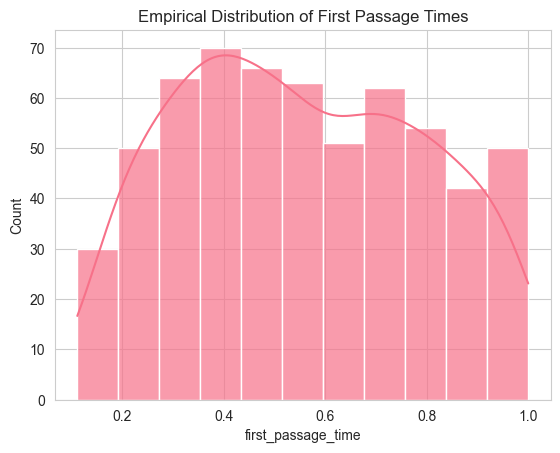

In [24]:
#| code-fold: true 
times_clean = (
    pl.Series(first_passage_times)
    .drop_nulls()
    .to_numpy()
)

# Create a DataFrame for seaborn
df_plot = pl.DataFrame({"first_passage_time": times_clean})

# Plot with seaborn
sns.histplot(data=df_plot, x="first_passage_time", kde=True, alpha = 0.7)
plt.title("Empirical Distribution of First Passage Times")
plt.show()

## Connections to Drift Diffusion Models and Wiener First Passage Time Distribution 

- [stan reference](https://mc-stan.org/docs/functions-reference/positive_lower-bounded_distributions.html#wiener-first-passage-time-distribution) 

Note that stan returns the first passage time of the accumulation process **over the upper boundary** only. To get the result for the lower boundary, use $$\text{Wiener}(y|\alpha, \tau, 1 - \beta, -\delta)$$

In [25]:
import cmdstanpy 

# stan model code for generating Wiener first passage time 
stan_model_code = """
data {
    int<lower=0> N; // number of smaples to generate 
    real alpha; // boundary separation 
    real tau; // non-decision time 
    real beta; // a-prior bias (0-1)
    real delta; // drift rate 
}
parameters {
    // None needed for sampling 
}
model {
    // Empty model block for sampling
}
generated quantities {
    vector[N] y; // first passage times 
    for (n in 1:N) {
        y[n] = wiener_rng(alpha, tau, beta, delta)
    }
}
"""

In [28]:
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns
# from scipy import stats

# def simulate_wiener_first_passage(alpha, tau, beta, delta, n_trials=1000):
#     """
#     Simulate first passage times for given parameters
#     """
#     # For delta=0, beta=0.5, we can use the chi-squared relationship
#     if abs(delta) < 1e-10 and abs(beta - 0.5) < 1e-10:
#         chi2_samples = np.random.chisquare(1, n_trials)
#         return tau + (alpha**2 * chi2_samples) / 2
#     else:
#         # For other parameters, use your simulation approach
#         # (You'd need to implement the full Wiener simulation here)
#         raise NotImplementedError("Implement full Wiener simulation for general parameters")

# def prior_predictive_check(n_simulations=100, n_trials_per_sim=1000):
#     """
#     Generate prior predictive samples
#     """
#     # Define your priors
#     alpha_prior = stats.gamma(a=2, scale=1)  # boundary separation
#     tau_prior = stats.expon(scale=0.1)       # non-decision time
#     beta_prior = stats.beta(a=2, b=2)        # starting point bias
#     delta_prior = stats.normal(0, 1)         # drift rate (this is what you care about!)
    
#     # Sample from priors
#     alpha_samples = alpha_prior.rvs(n_simulations)
#     tau_samples = tau_prior.rvs(n_simulations)
#     beta_samples = beta_prior.rvs(n_simulations)
#     delta_samples = delta_prior.rvs(n_simulations)
    
#     # Generate predicted data for each parameter set
#     predicted_data = []
#     for i in range(n_simulations):
#         if abs(delta_samples[i]) < 1e-10 and abs(beta_samples[i] - 0.5) < 1e-10:
#             # Use analytical solution when possible
#             chi2_samples = np.random.chisquare(1, n_trials_per_sim)
#             rt_samples = tau_samples[i] + (alpha_samples[i]**2 * chi2_samples) / 2
#         else:
#             # Use simulation for other cases
#             rt_samples = simulate_wiener_first_passage(
#                 alpha_samples[i], tau_samples[i], beta_samples[i], delta_samples[i], n_trials_per_sim
#             )
        
#         predicted_data.append({
#             'alpha': alpha_samples[i],
#             'tau': tau_samples[i],
#             'beta': beta_samples[i],
#             'delta': delta_samples[i],
#             'rt': rt_samples
#         })
    
#     return predicted_data

# # Run prior predictive check
# predicted_data = prior_predictive_check(n_simulations=50, n_trials_per_sim=500)

# # Visualize results
# fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# # 1. RT distributions for different drift values
# delta_values = np.linspace(-2, 2, 5)
# colors = plt.cm.viridis(np.linspace(0, 1, len(delta_values)))

# for i, delta_val in enumerate(delta_values):
#     # Find simulations close to this delta value
#     close_sims = [d for d in predicted_data if abs(d['delta'] - delta_val) < 0.2]
#     if close_sims:
#         all_rts = np.concatenate([d['rt'] for d in close_sims])
#         sns.histplot(all_rts, alpha=0.3, label=f'δ ≈ {delta_val:.1f}', 
#                     color=colors[i], ax=axes[0,0])

# axes[0,0].set_title('RT Distributions by Drift Rate')
# axes[0,0].set_xlabel('Reaction Time')
# axes[0,0].legend()

# # 2. Mean RT vs Drift Rate
# delta_vals = [d['delta'] for d in predicted_data]
# mean_rts = [np.mean(d['rt']) for d in predicted_data]
# axes[0,1].scatter(delta_vals, mean_rts, alpha=0.6)
# axes[0,1].set_xlabel('Drift Rate (δ)')
# axes[0,1].set_ylabel('Mean RT')
# axes[0,1].set_title('Mean RT vs Drift Rate')

# # 3. RT variance vs Drift Rate
# rt_vars = [np.var(d['rt']) for d in predicted_data]
# axes[1,0].scatter(delta_vals, rt_vars, alpha=0.6)
# axes[1,0].set_xlabel('Drift Rate (δ)')
# axes[1,0].set_ylabel('RT Variance')
# axes[1,0].set_title('RT Variance vs Drift Rate')

# # 4. Parameter correlations
# param_data = np.array([[d['alpha'], d['tau'], d['beta'], d['delta']] for d in predicted_data])
# param_names = ['α', 'τ', 'β', 'δ']
# corr_matrix = np.corrcoef(param_data.T)
# im = axes[1,1].imshow(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1)
# axes[1,1].set_xticks(range(len(param_names)))
# axes[1,1].set_yticks(range(len(param_names)))
# axes[1,1].set_xticklabels(param_names)
# axes[1,1].set_yticklabels(param_names)
# axes[1,1].set_title('Parameter Correlations')

# # Add correlation values
# for i in range(len(param_names)):
#     for j in range(len(param_names)):
#         text = axes[1,1].text(j, i, f'{corr_matrix[i, j]:.2f}',
#                              ha="center", va="center", color="black")

# plt.tight_layout()
# plt.show()